Step 1 — Load the data

In [3]:
import pandas as pd
df = pd.read_csv('superstore_csv_exp4.csv')
df['Order Date'] = pd.to_datetime(df['Order Date'])
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


Step 2 — Build the RFM table (one row per customer)

In [4]:
reference_date = df['Order Date'].max() + pd.Timedelta(days=1)
rfm = df.groupby('Customer ID').agg(
    Recency=('Order Date', lambda x: (reference_date - x.max()).days),
    Frequency=('Order ID', 'nunique'),
    Monetary=('Sales', 'sum')
).reset_index()
rfm.head()

,Customer ID,Recency,Frequency,Monetary
0,AA-10315,185,5,5563.560
1,AA-10375,20,9,1056.390
2,AA-10480,260,4,1790.512
3,AA-10645,56,6,5086.935
4,AB-10015,416,3,886.156


Step 3 — Scale the RFM values

In [5]:
from sklearn.preprocessing import StandardScaler
features = rfm[['Recency', 'Frequency', 'Monetary']]

scaled = StandardScaler().fit_transform(features)

Step 4 — Run k-means (k = 4)

In [6]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Segment'] = kmeans.fit_predict(scaled)
rfm.head()

,Customer ID,Recency,Frequency,Monetary,Segment
0,AA-10315,185,5,5563.560,0
1,AA-10375,20,9,1056.390,3
2,AA-10480,260,4,1790.512,0
3,AA-10645,56,6,5086.935,3
4,AB-10015,416,3,886.156,1


Step 5 — Describe each segment (the analysis)

In [7]:
summary = rfm.groupby('Segment')[['Recency', 'Frequency', 'Monetary']].mean()
summary['Customers'] = rfm.groupby('Segment').size()
summary.round(1)

,Recency,Frequency,Monetary,Customers
Segment,,,,
0,98.7,4.7,1615.7,340
1,546.1,3.8,1585.0,103
2,113.9,8.6,9449.9,67
3,70.6,8.7,3336.1,294


Step 6 — Visualize the segments

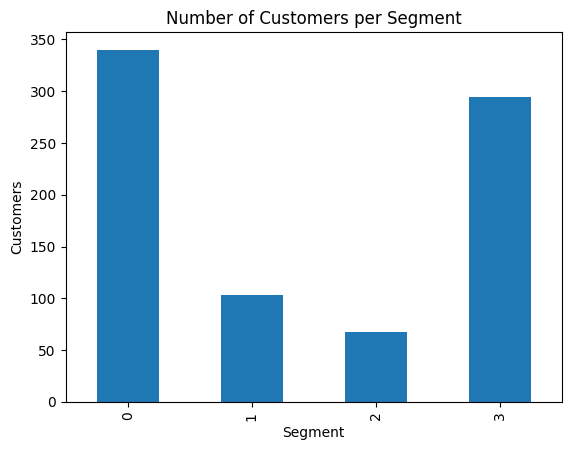

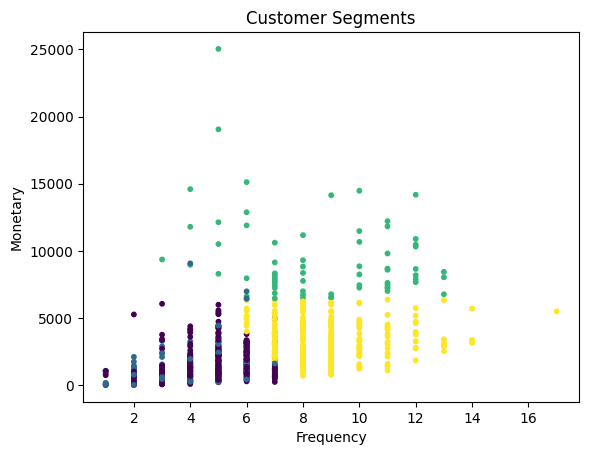

: 

In [ ]:
import matplotlib.pyplot as plt
# how many customers in each segment
rfm['Segment'].value_counts().sort_index().plot(kind='bar')
plt.title('Number of Customers per Segment')
plt.xlabel('Segment'); plt.ylabel('Customers')
plt.show()
# see the segments spread out by Frequency and Monetary
plt.scatter(rfm['Frequency'], rfm['Monetary'],
c=rfm['Segment'], cmap='viridis', s=10)
plt.xlabel('Frequency'); plt.ylabel('Monetary')
plt.title('Customer Segments'); plt.show()